# CashVec playground

Hands-on tour of the Python bindings: exact fingerprints, SimHash, the LSH index, and the dedup engine.

**Setup** (once, from the repo root):
```sh
source .venv/bin/activate
cd cashvec-py && maturin develop --release
```
Then select the `.venv` kernel and run the cells top to bottom.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import cashvec

rng = np.random.default_rng(42)

def unit(v):
    return v / np.linalg.norm(v)

def at_cosine(base, c):
    """A unit vector whose cosine with `base` is exactly `c` (up to float32 rounding)."""
    b = unit(base)
    w = rng.standard_normal(len(b)).astype(np.float32)
    w -= (w @ b) * b
    return (c * b + np.sqrt(1 - c * c) * unit(w)).astype(np.float32)

print("cashvec imported from", cashvec.__file__)

cashvec imported from /Users/radi/Projects/cashvec/cashvec-py/python/cashvec/__init__.py


## 1. Exact fingerprints

Identify vector *data*, not meaning. `-0.0` is canonicalized and the dimension is part of the input.

In [2]:
v = [0.12, 0.45, 0.78, 0.21]
print(cashvec.exact_fingerprint(v))
print("same vector, np.float64 :", cashvec.exact_fingerprint(np.array(v)) == cashvec.exact_fingerprint(v) or "differs (float64 rounds to a different f32)")
print("-0.0 == 0.0             :", cashvec.exact_fingerprint([0.0, 1.0]) == cashvec.exact_fingerprint([-0.0, 1.0]))
print("dimension matters       :", cashvec.exact_fingerprint([0.0]) != cashvec.exact_fingerprint([0.0, 0.0]))
print("1 ulp change differs    :", cashvec.exact_fingerprint(v) != cashvec.exact_fingerprint([0.12, 0.45, 0.78, 0.21000001]))

0c309483e547e0d097e4f3bfb8926624
same vector, np.float64 : True
-0.0 == 0.0             : True
dimension matters       : True
1 ulp change differs    : True


## 2. SimHash: Hamming distance vs. angle

Each signature bit differs with probability θ/π, so `cos θ ≈ cos(π · d / bits)`. More bits → tighter estimate.

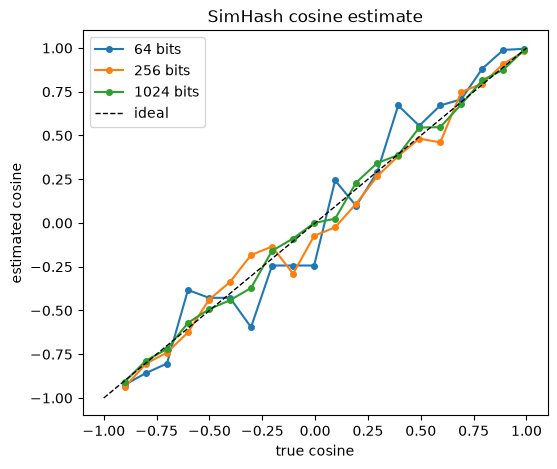

In [3]:
dim = 128
targets = np.linspace(-0.9, 0.99, 20)
fig, ax = plt.subplots(figsize=(6, 5))
for bits in (64, 256, 1024):
    h = cashvec.SimHasher(dim, bits)
    est = []
    for c in targets:
        a = rng.standard_normal(dim).astype(np.float32)
        b = at_cosine(a, c)
        est.append(h.hash(a).estimated_cosine(h.hash(b)))
    ax.plot(targets, est, "o-", ms=4, label=f"{bits} bits")
ax.plot([-1, 1], [-1, 1], "k--", lw=1, label="ideal")
ax.set_xlabel("true cosine"); ax.set_ylabel("estimated cosine"); ax.legend(); ax.set_title("SimHash cosine estimate")
plt.show()

In [4]:
h = cashvec.SimHasher(dim, 256)
a = rng.standard_normal(dim).astype(np.float32)
b = at_cosine(a, 0.95)
fa, fb = h.hash(a), h.hash(b)
print(repr(fa))
print("hamming:", fa.hamming_distance(fb), "/ 256   estimated cosine:", round(fa.estimated_cosine(fb), 3), "  true: 0.95")
print("similar at >= 0.8:", fa.is_similar_to(fb, 0.8))
print("scale invariant  :", h.hash(a * 100) == fa)
print("deterministic    :", cashvec.SimHasher(dim, 256).hash(a) == fa)
print("seed changes it  :", cashvec.SimHasher(dim, 256, seed=1).hash(a) != fa)

BinaryFingerprint(256 bits, 0x1bd077fc822a4651fa683984534eed23e5cf52f763811e1e67d47062c317e3c9)
hamming: 20 / 256   estimated cosine: 0.97   true: 0.95
similar at >= 0.8: True
scale invariant  : True
deterministic    : True
seed changes it  : True


## 3. Build an index

20,000 random 384-d vectors (typical sentence-embedding size).

In [5]:
N, DIM = 20_000, 384
data = rng.standard_normal((N, DIM)).astype(np.float32)
ids = [f"doc-{i}" for i in range(N)]

index = cashvec.VectorIndex(DIM)          # defaults: 16 tables x 12 bits
t = time.perf_counter()
index.insert_many(ids, data)
dt = time.perf_counter() - t
print(f"inserted {len(index):,} vectors in {dt:.2f}s ({N/dt:,.0f}/s)")
print(f"estimated index memory: {index.memory_usage()/2**20:.1f} MiB (raw vectors: {data.nbytes/2**20:.1f} MiB)")

inserted 20,000 vectors in 0.46s (43,262/s)
estimated index memory: 61.2 MiB (raw vectors: 29.3 MiB)


## 4. Search vs. brute force

Queries are noisy copies (cosine ≈ 0.96) of random indexed vectors, so each has a known true neighbour.

In [6]:
targets_idx = rng.integers(0, N, 200)
queries = np.stack([at_cosine(data[i], 0.96) for i in targets_idx])
THRESH, K = 0.9, 10

t = time.perf_counter(); approx = index.search_many(queries, K, THRESH); t_lsh = time.perf_counter() - t

# numpy brute force baseline (normalized matrix product)
norm_data = data / np.linalg.norm(data, axis=1, keepdims=True)
t = time.perf_counter()
sims = queries @ norm_data.T
exact = [[(ids[j], float(sims[q, j])) for j in np.argsort(-sims[q])[:K] if sims[q, j] >= THRESH] for q in range(len(queries))]
t_np = time.perf_counter() - t

found = total = 0
for a, e in zip(approx, exact):
    total += len(e); found += len({x[0] for x in a} & {x[0] for x in e})
print(f"CashVec LSH : {t_lsh/len(queries)*1e6:8.0f} us/query")
print(f"numpy brute : {t_np/len(queries)*1e6:8.0f} us/query")
print(f"recall@{K} (thr {THRESH}): {found/total:.3f}  ({found}/{total})")
print("planted neighbour found in every query:", all(ids[i] in {x[0] for x in a} for i, a in zip(targets_idx, approx)))
print("top result for query 0:", approx[0][:3])

CashVec LSH :      112 us/query
numpy brute :     1128 us/query
recall@10 (thr 0.9): 1.000  (200/200)
planted neighbour found in every query: True
top result for query 0: [('doc-12805', 0.9599999189376831)]


In [7]:
# Every returned hit is verified: nothing below the threshold, sorted best-first
assert all(s >= THRESH for a in approx for _, s in a)
assert all([s for _, s in a] == sorted([s for _, s in a], reverse=True) for a in approx)
# the index's own brute force must agree with numpy
q = queries[0]
print(index.search_brute_force(q, 3, THRESH))
print("candidates examined:", len(index.candidates(q)), "of", len(index))

[('doc-12805', 0.9599999189376831)]
candidates examined: 88 of 20000


## 5. Candidate probability vs. cosine

Theory: two vectors at angle θ share a bucket in one table with probability `p^k` (`p = 1 − θ/π`), and in at least one of `L` tables with `1 − (1 − p^k)^L`. Measured on the real index:

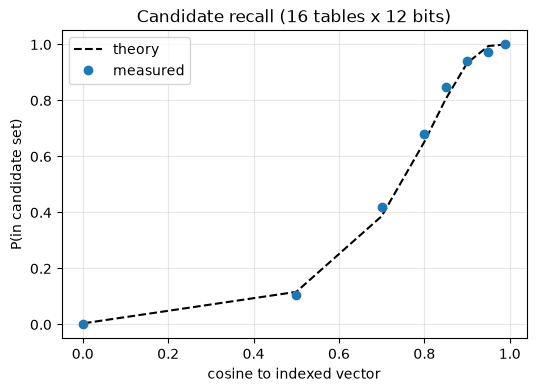

In [7]:
L, k = 16, 12
cos_grid = [0.99, 0.95, 0.9, 0.85, 0.8, 0.7, 0.5, 0.0]
measured = []
for c in cos_grid:
    hit = 0
    for i in rng.integers(0, N, 150):
        q = at_cosine(data[i], c)
        hit += f"doc-{i}" in index.candidates(q)
    measured.append(hit / 150)
theory = [1 - (1 - (1 - np.arccos(c) / np.pi) ** k) ** L for c in cos_grid]
plt.figure(figsize=(6, 4))
plt.plot(cos_grid, theory, "k--", label="theory")
plt.plot(cos_grid, measured, "o", label="measured")
plt.xlabel("cosine to indexed vector"); plt.ylabel("P(in candidate set)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Candidate recall (16 tables x 12 bits)"); plt.show()

## 6. Tuning: tables × bits

More tables raise recall (and candidate count); more bits per table make buckets more selective.

In [8]:
sub = data[:5000]; sub_ids = ids[:5000]
sub_q = np.stack([at_cosine(sub[i], 0.92) for i in range(0, 5000, 25)])
print(f"{'tables':>6} {'bits':>5} {'recall':>7} {'cands/query':>12} {'us/query':>9}")
for tables, bits in [(4, 12), (8, 12), (16, 12), (32, 12), (16, 8), (16, 16)]:
    ix = cashvec.VectorIndex(DIM, num_tables=tables, bits_per_table=bits)
    ix.insert_many(sub_ids, sub)
    ok = sum(sub_ids[i * 25] in {h[0] for h in ix.search(q, 10, 0.85)} for i, q in enumerate(sub_q))
    cands = np.mean([len(ix.candidates(q)) for q in sub_q])
    t = time.perf_counter(); ix.search_many(sub_q, 10, 0.85); us = (time.perf_counter() - t) / len(sub_q) * 1e6
    print(f"{tables:>6} {bits:>5} {ok/len(sub_q):>7.2f} {cands:>12.1f} {us:>9.0f}")

tables  bits  recall  cands/query  us/query
     4    12    0.58          5.5         6
     8    12    0.82         11.1        12
    16    12    0.98         21.6        24
    32    12    1.00         41.8        46
    16     8    1.00        310.7        54
    16    16    0.85          2.2        30


## 7. Deduplication engine

Plants near-duplicates in a stream of documents. The engine **reports** matches and never deletes anything.

In [9]:
engine = cashvec.DedupEngine(DIM, threshold=0.95)
base_docs = rng.standard_normal((1000, DIM)).astype(np.float32)
for i, v in enumerate(base_docs):
    engine.insert(f"orig-{i}", v)

stream = []   # (label, vector)
for i in range(0, 50):                      # exact copies
    stream.append((f"exact-of-{i}", base_docs[i].copy()))
for i in range(50, 100):                    # near duplicates
    stream.append((f"near-of-{i}", at_cosine(base_docs[i], 0.97)))
for i in range(50):                         # unrelated
    stream.append((f"new-{i}", rng.standard_normal(DIM).astype(np.float32)))

tp = fp = fn = 0
kinds = {"exact": 0, "near": 0}
for label, v in stream:
    matches = engine.find_similar(v)
    if label.startswith(("exact", "near")):
        want = f"orig-{label.rsplit('-', 1)[1]}"
        if any(m.id == want for m in matches): tp += 1
        else: fn += 1
        if matches and matches[0].exact: kinds["exact"] += 1
        elif matches: kinds["near"] += 1
    else:
        fp += len(matches)
print(f"detected {tp}/{tp+fn} planted duplicates, false positives on unrelated docs: {fp}")
print("reported as exact:", kinds["exact"], " as near:", kinds["near"])
print(engine.find_similar(stream[0][1])[:2])
print(engine.find_similar(stream[60][1])[:2])
print("documents still indexed (nothing deleted):", len(engine))

detected 100/100 planted duplicates, false positives on unrelated docs: 0
reported as exact: 50  as near: 50
[DuplicateMatch(id="orig-0", score=1.000000, exact=True)]
[DuplicateMatch(id="orig-60", score=0.970000, exact=False)]
documents still indexed (nothing deleted): 1000


In [11]:
# Streaming workflow: check, then insert
engine2 = cashvec.DedupEngine(DIM, threshold=0.95)
kept = skipped = 0
for i, (label, v) in enumerate(stream + [("orig", base_docs[0])]):
    dups = engine2.check_and_insert(f"s-{i}", v)
    skipped += bool(dups); kept += not dups
print(f"stream of {len(stream)+1}: first-seen={kept}, flagged as duplicate candidates={skipped}")

engine.remove("orig-0")
print("exact copy of orig-0 after removal:", engine.find_exact(base_docs[0]))

stream of 151: first-seen=150, flagged as duplicate candidates=1
exact copy of orig-0 after removal: []


## 8. Error handling

Invalid input raises `cashvec.CashVecError` (a `ValueError`); it never crashes the interpreter.

In [12]:
ix = cashvec.VectorIndex(3)
bad = {
    "NaN":            lambda: ix.insert("a", [1.0, float("nan"), 0.0]),
    "infinity":       lambda: ix.insert("a", [float("inf"), 0.0, 0.0]),
    "wrong dim":      lambda: ix.insert("a", [1.0, 2.0]),
    "empty":          lambda: ix.insert("a", []),
    "zero vector":    lambda: ix.insert("a", [0.0, 0.0, 0.0]),
    "bad threshold":  lambda: ix.search([1.0, 0.0, 0.0], 5, 1.5),
    "bad bits":       lambda: cashvec.VectorHasher(0).hash([1.0]),
}
for name, f in bad.items():
    try:
        f(); print(f"{name:14} -> no error?!")
    except cashvec.CashVecError as e:
        print(f"{name:14} -> {e}")
ix.insert("a", [1, 2, 3])
try:
    ix.insert("a", [3, 2, 1])
except ValueError as e:
    print(f"{'duplicate id':14} -> {e}")

NaN            -> vector contains NaN or infinity at index 1
infinity       -> vector contains NaN or infinity at index 0
wrong dim      -> dimension mismatch: expected 3, got 2
empty          -> vector is empty
zero vector    -> vector has zero norm
bad threshold  -> threshold must be a number in [-1, 1]
bad bits       -> invalid configuration: bits must be in 1..=4096, got 0
duplicate id   -> id already indexed: a
